[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_stormTracks_KKN_May2024_HID_doppler/blob/main/prep/P2_polar_products_hid.ipynb)


# P2 — Doppler, dual-pol และ HID บนกริด 1 km (เฉพาะ volume ที่มีพายุ)

**สำหรับผู้ดูแลข้อมูล** — ต้องรัน P1 และ PS ก่อน

ต่อ 1 volume ใช้ขั้นตอน `polar_tools.process_volume` ของ repo2/repo3 ทุกขั้น (dealias region-based แบบ tuned → divergence, azimuthal shear → ΦDP → KDP Vulpiani → แก้ ZDR bias → Z-PHI → HID Besic et al. 2016 → EDR PyTDA) แล้วแปลงลงกริดด้วย `track_tools.polar_volume_to_grid` ของ repo3 **ตัวแปร ชื่อ หน่วย และทิศของกริดเหมือน `KKN_20240503_polar_15min.nc` ของ repo3** ฟังก์ชัน `cell_table` จึงใช้ได้ทันที

**ต่างจากงานเดิม 3 จุด (มีเหตุผลกำกับ)**
1. **อุณหภูมิ:** ใช้โปรไฟล์รายวันจาก PS (`data/sounding/may2024_hid_profiles.nc`) แทนการใช้ sounding ไฟล์เดียว
2. **เครื่องหมาย ΦDP = −1 คงที่:** `process_phidp` เดิมตรวจเครื่องหมายอัตโนมัติรายมุมยก เมื่อมุมยกมี ray ที่ใช้คำนวณความชันไม่พอ ค่าความชันเป็น NaN และถูกตีความเป็น +1 (ไม่กลับเครื่องหมาย) ทั้งที่ ray ที่มีข้อมูลยังถูกประมวลผล ใน 92 volume ของ 3 พ.ค. เกิดกรณีนี้ 27–53 volume ต่อมุมยก KKN มี ΦDP ลดลงตามระยะทุกมุมยก (repo2) ความชันอัตโนมัติยังเก็บไว้ในคอลัมน์ `phidp_slope_s0…s3`
3. **กริด ZDR:** ค่านอก −4…8 dB ถูกตั้งเป็นค่าขาด (ขอบของ Z-PHI ทำให้บาง gate มีค่าเกิน 100 dB)

ทดสอบแล้ว: volume 09:30 UTC ของ 3 พ.ค. ได้กริด Zc, vel, kdp, hid_s0, hail_col **ตรงกับไฟล์ของ repo3 100%**

| ผลลัพธ์ใน `KKN_derived_v1/` | เนื้อหา |
|---|---|
| `polar/KKN_YYYYMMDD_polar_15min.nc` | Zc, vel, div, azshear, edr, kdp, zdr, hid_s0–s3, hail_col, graupel_col (~0.2 MB/ภาพ) |
| `metrics/…`, `volume_metrics_p2.csv` | ตัวชี้วัดต่อ volume (แบบ repo2 NB06) + แหล่งที่มาของโปรไฟล์อุณหภูมิ |
| `hid_sensitivity_20240503.csv` | HID เปลี่ยนไปเท่าไรเมื่อใช้โปรไฟล์ต่างแบบ |

**Runtime:** CPU + High-RAM ~11 วินาที/volume/core

In [10]:
# @title ⚙️ เตรียมสภาพแวดล้อม (รันก่อนเสมอ)
import os, sys, subprocess
REPO = "Teach_stormTracks_KKN_May2024_HID_doppler"
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/nattaponm/{REPO}.git", f"/content/{REPO}"], check=True)
    else:
        subprocess.run(["git", "-C", f"/content/{REPO}", "pull", "-q"])
    os.chdir(f"/content/{REPO}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt", "arm_pyart"], check=True)
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-build-isolation",
                        "git+https://github.com/nasa/PyTDA.git"])
    print("PyTDA:", "ติดตั้งแล้ว" if r.returncode == 0 else "ติดตั้งไม่สำเร็จ — จะข้าม EDR")
elif os.path.basename(os.getcwd()) in ("notebooks", "prep"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("โฟลเดอร์ทำงาน:", os.getcwd(), "| CPU", os.cpu_count(), "core")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTDA: ติดตั้งแล้ว
โฟลเดอร์ทำงาน: /content/Teach_stormTracks_KKN_May2024_HID_doppler | CPU 8 core


In [11]:
import json, time, shutil, warnings
from pathlib import Path
from functools import partial
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mproc
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings("ignore")

from utils.config import load_settings, repo_path
from utils import maps as M
s = load_settings()
M.setup_style()
OUT_ROOT = Path(os.environ.get("KKN_OUT_ROOT", s["radar_data"]["drive_derived_root"]))
N_WORKERS = os.cpu_count()
CTX = mproc.get_context("fork")

from utils import radar_inventory as RI, radar_prep as RP, derived_io as DIO, sounding as S
from utils import polar_tools as pt, track_tools as tt
RAW_ROOT = Path(os.environ.get("KKN_RAW_ROOT", s["radar_data"]["drive_raw_root"]))
assert RAW_ROOT.exists(), f"ไม่พบ {RAW_ROOT}"
POLAR_DIR, MET_DIR = OUT_ROOT / "polar", OUT_ROOT / "metrics"
for d in (POLAR_DIR, MET_DIR):
    d.mkdir(parents=True, exist_ok=True)
try:
    import pytda  # noqa: F401
    DO_EDR = True
except Exception:
    DO_EDR = False
print("คำนวณ EDR (PyTDA):", DO_EDR)
PROF = xr.open_dataset(repo_path("data", "sounding", "may2024_hid_profiles.nc")).load()
PSUM = pd.read_csv(repo_path("data", "sounding", "may2024_hid_profile_summary.csv"), parse_dates=["day"]).set_index("day")
with xr.open_dataset(sorted((OUT_ROOT / "cappi").glob("KKN_*_cappi_15min.nc"))[0]) as _d:
    SITE = {"lat": _d.attrs["radar_latitude"], "lon": _d.attrs["radar_longitude"], "alt": _d.attrs["radar_altitude_m"]}

#DAYS = ["20240503"]     # ← รอบแรก | ทั้งเดือน: DAYS = None
DAYS = None    # ← รอบแรก | ทั้งเดือน: DAYS = None
OVERWRITE = False

คำนวณ EDR (PyTDA): True


## 1. เลือก volume ที่มีพายุ (จากสถิติ P1)

เกณฑ์: pseudo-CAPPI ≥ 35 dBZ อย่างน้อย 20 km² และช่องข้างเคียง ±1 (15 นาที) — ปรับได้ใน `config/settings.yaml`

In [12]:
st = pd.read_csv(OUT_ROOT / "volume_stats_p1.csv", parse_dates=["slot_utc"])
st = st[st["status"] == "ok"].sort_values("slot_utc")
thr, nb_ = s["radar_data"]["p2_active_area35_km2"], s["radar_data"]["p2_neighbor_slots"]
active = set()
for t in st.loc[st["area_ge35_km2"] >= thr, "slot_utc"]:
    active.update(t + pd.Timedelta(minutes=15 * k) for k in range(-nb_, nb_ + 1))
files = RI.assign_slots(RI.list_files(RAW_ROOT, s, "2405"), s)
files = files[files["status"].isin(["ok", "offset", "small"]) & files["slot_utc"].isin(active)].copy()
files["day"] = files["slot_utc"].dt.strftime("%Y%m%d")
days = sorted(files["day"].unique()) if DAYS is None else [d for d in DAYS if d in set(files["day"])]
print(f"volume ที่มีพายุ {len(files)} จาก {len(st)} ({100 * len(files) / max(len(st), 1):.0f}%) | "
      f"ประมาณ {len(files) * 11 / N_WORKERS / 60:.0f} นาทีบน {N_WORKERS} core (ทั้งเดือน)")
files.groupby("day").size().rename("volume").to_frame().T

volume ที่มีพายุ 2178 จาก 2962 (74%) | ประมาณ 50 นาทีบน 8 core (ทั้งเดือน)


day,20240501,20240502,20240503,20240504,20240505,20240506,20240507,20240508,20240509,20240510,...,20240521,20240522,20240523,20240524,20240525,20240526,20240527,20240529,20240530,20240531
volume,55,52,80,80,88,91,63,80,73,94,...,82,84,96,85,86,57,50,54,72,91


## 2. ประมวลผลทีละวัน (ขนาน) — โปรไฟล์อุณหภูมิของวันนั้นจาก PS

In [13]:
def process_day(day):
    out_nc, out_csv = POLAR_DIR / f"KKN_{day}_polar_15min.nc", MET_DIR / f"KKN_{day}_p2_metrics.csv"
    if out_nc.exists() and out_csv.exists() and not OVERWRITE:
        return "skip", 0.0
    t0 = time.time()
    f = files[files["day"] == day].sort_values("slot_utc")
    d = pd.Timestamp(day)
    profile = S.profile_dataframe(PROF, d)
    work = partial(RP.p2_volume, profile_df=profile, do_edr=DO_EDR)
    rows, T, G = [], [], {k: [] for k in tt.POLAR_VARS}
    with ProcessPoolExecutor(N_WORKERS, mp_context=CTX) as ex:
        for m, g in ex.map(work, f["path"], f["slot_utc"]):
            rows.append(m)
            if g is None:
                continue
            T.append(m["slot_utc"])
            for k in G:
                G[k].append(g[k])
    met = pd.DataFrame(rows).sort_values("slot_utc")
    met["hid_profile_source"] = PSUM.loc[d, "hid_profile_source"]
    met["z0C_m"] = PSUM.loc[d, "z0C_m"]
    met.to_csv(out_csv, index=False)
    if T:
        o = np.argsort(T)
        DIO.write_polar_day(out_nc, [T[i] for i in o], {k: np.stack(v)[o] for k, v in G.items()}, SITE,
                            {"hid_profile_source": PSUM.loc[d, "hid_profile_source"], "z0C_m": float(PSUM.loc[d, "z0C_m"]),
                             "edr_computed": int(DO_EDR)})
    size = out_nc.stat().st_size / 1e6 if out_nc.exists() else 0
    return f"{len(T)}/{len(f)} ok, {size:.1f} MB, โปรไฟล์ {PSUM.loc[d, 'hid_profile_source']}", time.time() - t0

t_all = time.time()
for k, day in enumerate(days, 1):
    msg, dt = process_day(day)
    n = int((files["day"] == day).sum())
    print(f"[{k:2d}/{len(days)}] {day}: {msg}" + (f" | {dt / 60:.1f} นาที ({dt / max(n, 1):.1f} วินาที/volume)" if dt else ""))
print(f"รวม {(time.time() - t_all) / 60:.1f} นาที")

[ 1/30] 20240501: 55/55 ok, 0.9 MB, โปรไฟล์ own | 1.5 นาที (1.7 วินาที/volume)
[ 2/30] 20240502: 52/52 ok, 1.1 MB, โปรไฟล์ own | 1.4 นาที (1.6 วินาที/volume)
[ 3/30] 20240503: skip
[ 4/30] 20240504: 80/80 ok, 3.4 MB, โปรไฟล์ own | 2.8 นาที (2.1 วินาที/volume)
[ 5/30] 20240505: 88/88 ok, 4.7 MB, โปรไฟล์ own | 3.0 นาที (2.1 วินาที/volume)
[ 6/30] 20240506: 91/91 ok, 13.2 MB, โปรไฟล์ own | 3.7 นาที (2.4 วินาที/volume)
[ 7/30] 20240507: 63/63 ok, 4.0 MB, โปรไฟล์ spliced | 2.2 นาที (2.0 วินาที/volume)
[ 8/30] 20240508: 80/80 ok, 5.8 MB, โปรไฟล์ spliced | 3.0 นาที (2.3 วินาที/volume)
[ 9/30] 20240509: 73/73 ok, 9.1 MB, โปรไฟล์ own | 3.2 นาที (2.6 วินาที/volume)
[10/30] 20240510: 94/94 ok, 20.0 MB, โปรไฟล์ own | 4.9 นาที (3.1 วินาที/volume)
[11/30] 20240511: 63/63 ok, 6.5 MB, โปรไฟล์ own | 2.5 นาที (2.4 วินาที/volume)
[12/30] 20240512: 66/66 ok, 3.5 MB, โปรไฟล์ neighbor_mean(11,13) | 2.4 นาที (2.2 วินาที/volume)
[13/30] 20240513: 68/68 ok, 19.3 MB, โปรไฟล์ own | 3.7 นาที (3.3 วินาที/volume)
[

In [14]:
met = pd.concat([pd.read_csv(p, parse_dates=["slot_utc"]) for p in sorted(MET_DIR.glob("KKN_*_p2_metrics.csv"))], ignore_index=True)
for p in (OUT_ROOT / "volume_metrics_p2.csv", repo_path("data", "derived", "volume_metrics_p2.csv")):
    met.to_csv(p, index=False)
print("สถานะ:", met["status"].value_counts().to_dict())
if (met["status"] != "ok").any():
    display(met.loc[met["status"] != "ok", ["slot_utc", "error"]].head(10))

สถานะ: {'ok': 2178}


## 3. ตรวจเทียบกับ repo3 (3 พ.ค. 09:30 UTC)

ที่เวลานี้เครื่องหมาย ΦDP อัตโนมัติของโค้ดเดิมเป็น −1 ทุกมุมยกอยู่แล้ว และโปรไฟล์ของวันที่ 3 คือ sounding ไฟล์เดียวกับ repo3 กริดจึงควรตรงกันทุก pixel

In [15]:
for d in ("derived", "days", "inventory", "reports"):
    os.makedirs(f"data/{d}", exist_ok=True)

In [16]:
import urllib.request
mine = POLAR_DIR / "KKN_20240503_polar_15min.nc"
t930 = pd.Timestamp("2024-05-03 09:30")
if mine.exists():
    urllib.request.urlretrieve("https://raw.githubusercontent.com/nattaponm/Teach_Tdating_strom_tracks_HID_CloudProperties/"
                               "main/data/derived/KKN_20240503_polar_15min.nc", "ref_polar.nc")
    A, ta = tt.load_polar_grid(str(mine)); B, tb = tt.load_polar_grid("ref_polar.nc")
    if t930 in set(ta) and t930 in set(tb):
        i, j = list(ta).index(t930), list(tb).index(t930)
        rows = []
        for v in ("Zc", "vel", "kdp", "zdr", "hid_s0", "hid_s2", "hail_col"):
            a, b = A[v][i].astype(float), B[v][j].astype(float)
            ok = np.isfinite(a) & np.isfinite(b)
            rows.append({"ตัวแปร": v, "pixel ร่วม": int(ok.sum()), "ตรงกัน (%)": 100 * np.mean(np.abs(a[ok] - b[ok]) <= 0.06)})
        display(pd.DataFrame(rows).round(2))

,ตัวแปร,pixel ร่วม,ตรงกัน (%)
0,Zc,9684,100.00
1,vel,6259,98.93
2,kdp,13694,100.00
3,zdr,9615,100.00
4,hid_s0,231361,100.00
5,hid_s2,231361,100.00
6,hail_col,231361,100.00


## 4. ความไวของ HID ต่อโปรไฟล์อุณหภูมิ (3 พ.ค. 09:30 UTC)

จำแนกซ้ำด้วย 4 โปรไฟล์: ของวันนั้น (`own`), ค่าเฉลี่ยวันที่ 2 และ 4, composite ทั้งเดือน และ **"โปรไฟล์สั้นแบบ 12 พ.ค."** (sounding ถูกตัดที่ 1.1 km แล้วใช้ `np.interp` แบบเดิม) ผลนี้บอกขนาดความไม่แน่นอนจากการต่อเติม และบอกว่าข้อผิดพลาดเดิมรุนแรงแค่ไหน

In [17]:
f930 = files[files["slot_utc"] == t930]
if len(f930):
    z = PROF["height"].values
    own = S.profile_dataframe(PROF, "2024-05-03")
    nbm = pd.DataFrame({"height": z, "temperature": 0.5 * (PROF["temperature"].sel(day="2024-05-02").values +
                                                         PROF["temperature"].sel(day="2024-05-04").values)})
    comp = pd.DataFrame({"height": z, "temperature": PROF["composite_temperature"].values})
    short = own[own["height"] <= 1100].copy()          # เลียนแบบ sounding สั้นของ 12 พ.ค.
    sens = RP.hid_sensitivity(f930["path"].iloc[0], {"own": own, "neighbor_mean(2,4)": nbm, "composite": comp,
                                                     "สั้น 1.1 km (np.interp เดิม)": short})
    sens.to_csv(OUT_ROOT / "hid_sensitivity_20240503.csv"); sens.to_csv(repo_path("data", "derived", "hid_sensitivity_20240503.csv"))
    display(sens.round(1))

,n_classified,changed_pct,AG,CR,LR,RP,RN,VI,WS,MH,IH/HDG
profile,,,,,,,,,,,
own,42087,0.0,14.2,0.6,38.2,4.3,15.5,15.4,5.2,3.6,3.0
"neighbor_mean(2,4)",42087,4.6,14.7,0.7,36.5,4.5,14.4,16.1,6.5,3.5,3.2
composite,42087,1.4,13.6,0.6,38.3,4.2,15.5,15.0,6.2,3.6,2.9
สั้น 1.1 km (np.interp เดิม),42087,42.8,0.0,0.0,69.8,0.0,26.2,0.0,0.0,4.0,0.0


## 5. ภาพรวม: จำนวน volume ที่พบลูกเห็บในคอลัมน์ และพื้นที่ลูกเห็บรายวัน

บันทึกรูป → /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1/figures/p2_hail_overview.png / .pdf


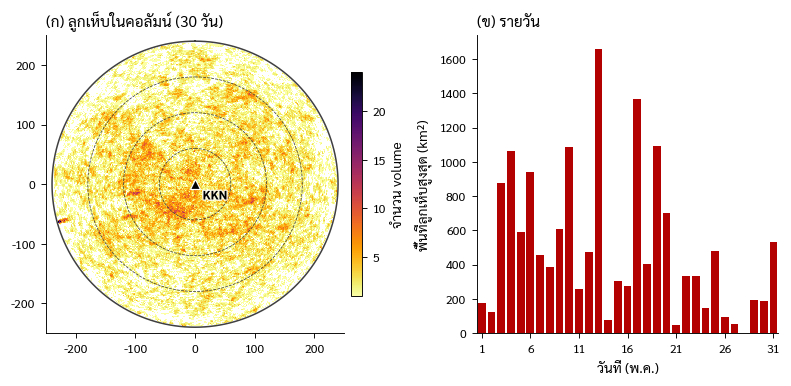

In [18]:
ncs = sorted(POLAR_DIR.glob("KKN_*_polar_15min.nc"))
if ncs:
    acc = None
    for p in ncs:
        with xr.open_dataset(p) as d:
            h = d["hail_col"].sum("time").values.astype(float)
            acc = h if acc is None else acc + h
    x = RP.grid_axes()[0] / 1e3
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.4), gridspec_kw={"width_ratios": [1.15, 1]}, layout="constrained")
    ax = axs[0]
    im = ax.pcolormesh(x, x[::-1], np.where(acc > 0, acc, np.nan), cmap="inferno_r", shading="auto")
    M.add_range_rings(ax, s, label=False)
    ax.set_xlim(-250, 250); ax.set_ylim(-250, 250); ax.set_aspect("equal")
    fig.colorbar(im, ax=ax, shrink=0.75, pad=0.02, label="จำนวน volume")
    ax.set_title(f"(ก) ลูกเห็บในคอลัมน์ ({len(ncs)} วัน)", loc="left")
    d = met[met["status"] == "ok"].copy(); d["day"] = d["slot_utc"].dt.day
    mx = d.groupby("day")["area_hail_km2"].max()
    axs[1].bar(mx.index, mx.values, color="#b30000")
    axs[1].set_xlim(0.5, 31.5); axs[1].set_xticks(range(1, 32, 5))
    axs[1].set_xlabel("วันที่ (พ.ค.)"); axs[1].set_ylabel("พื้นที่ลูกเห็บสูงสุด (km²)")
    axs[1].set_title("(ข) รายวัน", loc="left")
    M.savefig(fig, "p2_hail_overview", outdir=OUT_ROOT / "figures")
    plt.show()

**ขั้นต่อไป:** `DAYS = None` รันทั้งเดือน แล้วรัน P3 (ติดตามพายุ)